# Jalachakra — 02 · Data preparation for the crop-water study

**What this notebook is for.** It turns the files in `datasets/` into the
analysis-ready tables the rest of the study depends on, and it produces the
evidence for three decisions that everything downstream rests on:

1. whether the supplied `water_requirement_liters` column can serve as
   supervised ground truth;
2. what can legitimately be said about where the weather series was recorded;
3. which columns are safe to hand to a model and which are not.

**How to run it.** Kernel → Restart & Run All. It is self-contained: it does not
use any variable defined in notebook 01, and every path is resolved relative to
the repository, so it works from any machine and any working directory.

**Where the logic lives.** The notebook is a driver. The work happens in the
modules under `ml/`, which are unit-tested in `tests/`. That way a number shown
here can be reproduced by a script or a test, and the two cannot drift apart.

**Outputs.** Analysis-ready tables in `datasets/processed/`, evidence tables and
a written report in `reports/data_quality/`, figures in `reports/figures/`.
`datasets/raw/` is never written to; the notebook hashes it to prove that.


## 1 · Setup

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

# Make the repository importable whether this notebook is opened from the
# repository root or from notebooks/.
_here = Path.cwd()
PROJECT_ROOT = _here if (_here / "ml").is_dir() else _here.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml import config, data_loader, quality_report
from ml.logging_utils import setup_logging

setup_logging("INFO")
config.ensure_directories()

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
matplotlib.rcParams.update({"figure.dpi": 110, "figure.autolayout": True,
                            "axes.grid": True, "grid.alpha": 0.25})

RUN_TIMESTAMP = config.run_timestamp()
print(f"project root : {PROJECT_ROOT}")
print(f"run          : {RUN_TIMESTAMP}")
print(f"random seed  : {config.RANDOM_SEED}")
print(f"pandas {pd.__version__} · numpy {np.__version__}")


project root : D:\Projects\JALACHAKRA\AgriHydro
run          : 2026-09-18T17:37:18Z
random seed  : 20260918
pandas 2.2.3 · numpy 2.1.3


## 2 · What is in the repository, and what each file is for

Every dataset is declared in `ml/data_loader.py` with a **tier** that fixes its
role in the study:

| tier | meaning |
|---|---|
| `primary` | feeds the research path directly |
| `reference` | supplies agronomic constants (stage lengths, crop coefficients) |
| `supporting` | context only; never a modelling input on its own |
| `excluded` | kept for the audit trail, deliberately outside the research path |

Declaring this up front stops a file drifting into the modelling path later
just because it happens to contain a column with a familiar name.


In [2]:
registry = data_loader.registry_frame()
display(registry[["key", "tier", "raw_file", "cleaned_file", "raw_exists", "cleaned_exists"]])

print("\nRole of each file:\n")
for _, row in registry.iterrows():
    print(f"  [{row['tier']:>10}] {row['key']}")
    print(f"               {row['role']}")
    print(f"               {row['notes']}\n")


,key,tier,raw_file,cleaned_file,raw_exists,cleaned_exists
0,climate,primary,Climate_Data.csv,Climate_Data_cleaned.csv,True,True
1,crop_calendar,reference,Crop_Calender.csv,Crop_Calender_cleaned.csv,True,True
2,growth_stage_reference,reference,Karnataka_Crop_Growth_Stage_Reference.xlsx,Karnataka_Crop_Growth_Stage_Reference_cleaned.csv,True,True
3,crop_recommendation,primary,Crop_recommendation.csv,Crop_recommendation_cleaned.csv,True,True
4,soil,supporting,Soil data.csv,Soil_data_cleaned.csv,True,True
5,rainfall_district,supporting,Rainfall_2016_districtwise.csv,Rainfall_2016_districtwise_cleaned.csv,True,True
6,crop_water,excluded,crop_water_data.csv,crop_water_data_cleaned.csv,True,True
7,season_context,supporting,data_season.csv,data_season_supporting_cleaned.csv,True,True
8,crop_generic,excluded,crop_dataset.csv,-,True,False



Role of each file:

  [   primary] climate
               Daily meteorological series driving ET0.
               Column names match the NASA POWER daily-point parameter set exactly (T2M, RH2M, WS2M, PRECTOTCORR, ALLSKY_SFC_SW_DWN), which fixes the units but not the location: no latitude/longitude column is present.

  [ reference] crop_calendar
               Stage durations, rooting depth and Kc for five crops.
               The ETo/ETc columns are the compiler's own worked example, not measurements, and are not used as data. Only Kc, stage duration, root depth and water-holding capacity are consumed.

  [ reference] growth_stage_reference
               Growth-stage-aware Kc references for paddy, finger millet and maize.
               Kc values are held as free text with ranges and citations; ml/crop_reference.py parses them under documented rules.

  [   primary] crop_recommendation
               Agronomic suitability samples for the crop-recommendation module.
               F

## 3 · The raw files are read-only

The study commits to leaving `datasets/raw/` untouched. Rather than assert that,
hash it. The same hashes are printed again at the end of the notebook, so the
claim is checkable within a single run.


In [3]:
fingerprints_before = data_loader.raw_fingerprint()
display(fingerprints_before.assign(sha256=lambda d: d["sha256"].str.slice(0, 16) + "…"))
print(f"{len(fingerprints_before)} raw files, "
      f"{fingerprints_before['size_bytes'].sum():,} bytes total")


,filename,size_bytes,sha256
0,Climate_Data.csv,148903,e2fec7864c867f9c…
1,Crop_Calender.csv,1381,d5925caa199f47b4…
2,crop_dataset.csv,116156,5c41683eeafb9ba8…
3,Crop_recommendation.csv,147833,808e1d84a544647f…
4,crop_water_data.csv,818553,05d00c5702a684bd…
5,data_season.csv,224008,57cdfccf559f1efa…
6,Karnataka_Crop_Growth_Stage_Reference.xlsx,8624,8988617bbb5300ad…
7,Rainfall_2016_districtwise.csv,1050,97bbcff2e67f0328…
8,Soil data.csv,32380,47fc7ac20cb571f6…


9 raw files, 1,498,888 bytes total


## 4 · What the earlier cleaning pass actually did

The repository arrived with a `datasets/cleaned/` directory produced by earlier
work. Inheriting it without knowing what was changed is not an acceptable
starting point, so every cleaned file is diffed against its untouched original.

Anything this table reports as changed is a transformation somebody applied, and
the study has to be able to name it.


In [4]:
from ml import data_cleaner

audits = []
for key, spec in data_loader.DATASETS.items():
    if spec.cleaned_filename is None:
        continue
    audits.append(
        data_cleaner.audit_raw_versus_cleaned(
            data_loader.load_dataset(key, stage="raw"),
            data_loader.load_dataset(key, stage="cleaned"),
            key,
        )
    )
raw_vs_cleaned = pd.concat(audits, ignore_index=True)
display(raw_vs_cleaned[raw_vs_cleaned["changed"]])

unchanged = raw_vs_cleaned[~raw_vs_cleaned["changed"]]["dataset"].nunique()
print(f"\n{len(raw_vs_cleaned[raw_vs_cleaned['changed']])} difference(s) detected "
      f"across {raw_vs_cleaned['dataset'].nunique()} dataset(s).")


INFO    ml.data_loader           loaded climate                [raw]         2557 rows x 11 cols  <- Climate_Data.csv


INFO    ml.data_loader           loaded climate                [cleaned]     2557 rows x 11 cols  <- Climate_Data_cleaned.csv


WARNING ml.data_loader           Crop_Calender.csv is not valid UTF-8; re-reading as latin-1


INFO    ml.data_loader           loaded crop_calendar          [raw]           25 rows x 14 cols  <- Crop_Calender.csv


INFO    ml.data_loader           loaded crop_calendar          [cleaned]       25 rows x  9 cols  <- Crop_Calender_cleaned.csv


...

INFO    ml.data_loader           loaded crop_water             [cleaned]    10000 rows x 14 cols  <- crop_water_data_cleaned.csv


INFO    ml.data_loader           loaded season_context         [raw]         3158 rows x 12 cols  <- data_season.csv


INFO    ml.data_loader           loaded season_context         [cleaned]     3158 rows x 10 cols  <- data_season_supporting_cleaned.csv


,dataset,aspect,raw,cleaned,changed
2,climate,missing[allsky_sfc_sw_dwn],0.0000,1.0000,True
3,climate,min[allsky_sfc_sw_dwn],-999.0000,1.5800,True
5,crop_calendar,column_count,14,9,True
6,crop_calendar,columns_dropped,"[unnamed_10, unnamed_11, unnamed_12, unnamed_1...",-,True
7,crop_calendar,columns_added,-,[],True
8,crop_calendar,missing[kc],1,5,True
9,crop_calendar,missing[reference_eto_mm_day_source],0,5,True
10,crop_calendar,missing[season_effective_rainfall_mm_source],0,20,True
22,season_context,column_count,12,10,True
23,season_context,columns_dropped,"[temperature, yield_value]",-,True



11 difference(s) detected across 8 dataset(s).


**Reading this table.** The only substantive inherited change is in the climate
file: one `ALLSKY_SFC_SW_DWN` value of `-999` became a missing value. `-999` is
the provider's no-observation sentinel, so converting it to NaN was correct, and
it is now a genuine gap this notebook has to fill in section 8. Row counts and
column counts are untouched everywhere, so no records were dropped.


## 5 · Column profiles

Shape, type, missingness, cardinality and range for every column in every file,
before any cleaning of our own.


In [5]:
from ml import data_validator

loaded = data_loader.load_all()
profiles_before = pd.concat(
    [data_validator.profile(frame, name) for name, frame in loaded.items()],
    ignore_index=True,
)
display(profiles_before)


INFO    ml.data_loader           loaded climate                [cleaned]     2557 rows x 11 cols  <- Climate_Data_cleaned.csv


INFO    ml.data_loader           loaded crop_calendar          [cleaned]       25 rows x  9 cols  <- Crop_Calender_cleaned.csv


INFO    ml.data_loader           loaded growth_stage_reference [cleaned]       13 rows x  7 cols  <- Karnataka_Crop_Growth_Stage_Reference_cleaned.csv


INFO    ml.data_loader           loaded crop_recommendation    [cleaned]     2200 rows x  8 cols  <- Crop_recommendation_cleaned.csv


INFO    ml.data_loader           loaded soil                   [cleaned]      875 rows x  5 cols  <- Soil_data_cleaned.csv


...

INFO    ml.data_loader           loaded crop_water             [cleaned]    10000 rows x 14 cols  <- crop_water_data_cleaned.csv


INFO    ml.data_loader           loaded season_context         [cleaned]     3158 rows x 10 cols  <- data_season_supporting_cleaned.csv


INFO    ml.data_loader           loaded crop_generic           [cleaned]     5000 rows x  4 cols  <- crop_dataset.csv


C:\Users\chandanap\AppData\Local\Temp\ipykernel_36516\3402186816.py:4: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  profiles_before = pd.concat(


,dataset,column,dtype,missing,missing_pct,unique,min,max,mean
0,climate,datetime,object,0,0.0000,2557,NaN,NaN,NaN
1,climate,date,int64,0,0.0000,31,1.0000,31.0000,15.7309
2,climate,month,int64,0,0.0000,12,1.0000,12.0000,6.5225
3,climate,year,int64,0,0.0000,7,"2,018.0000","2,024.0000","2,021.0008"
4,climate,t2m,float64,0,0.0000,1284,13.4900,36.7000,26.6209
...,...,...,...,...,...,...,...,...,...
70,season_context,season,object,0,0.0000,3,NaN,NaN,NaN
71,crop_generic,temperature,float64,0,0.0000,1836,20.0000,39.9900,29.9366
72,crop_generic,humidity,float64,0,0.0000,3445,30.0000,89.9700,59.4892
73,crop_generic,rainfall_mm,float64,0,0.0000,3164,0.0100,49.9900,25.0688


## 6 · Where was the weather recorded?

FAO-56 Penman–Monteith needs latitude (for extraterrestrial radiation) and
elevation (for barometric pressure and the clear-sky ceiling). The weather file
has neither, and inventing a coordinate is not acceptable.

Note first what the column names do tell us. `T2M`, `RH2M`, `WS2M`,
`PRECTOTCORR` and `ALLSKY_SFC_SW_DWN` are the parameter names of a NASA POWER
daily point export. That fixes the **units** exactly — degrees Celsius, percent,
metres per second *at two metres*, millimetres per day, and MJ m⁻² day⁻¹ — which
is why no unit conversion is applied anywhere in `ml/et0.py`, and why the
FAO-56 wind-height correction is deliberately skipped. What it does not fix is
the **location**, because a POWER export does not carry its own coordinates.

So the notebook does two separate things: it estimates what it can, and it
bounds what it cannot.


### 6.1 · Estimating latitude from the radiation series

On a cloud-free day, incoming shortwave radiation approaches the clear-sky
ceiling, so the clearness index `Kt = Rs / Ra(latitude, day-of-year)` should
reach about the same value on the clearest day of every month. Latitude controls
how hard `Ra` swings through the year — almost flat at the equator, strongly
seasonal further north — so the latitude that flattens the month-to-month
profile of the high-percentile `Kt` is the one most consistent with the data.

Only rain-free dry-season days are used, because monsoon months never produce a
clear sky.


In [6]:
from ml import site_inference

weather_in = data_loader.load_dataset("climate")
latitude_estimate = site_inference.estimate_latitude(weather_in)

print(latitude_estimate.describe())
print()
profile = latitude_estimate.profile
display(profile[profile["latitude_deg"] % 2 == 0].round(4).head(20))


INFO    ml.data_loader           loaded climate                [cleaned]     2557 rows x 11 cols  <- Climate_Data_cleaned.csv


INFO    ml.site_inference        latitude estimate 23.75 degN (resampling 23.71 +/- 0.25; objective within 1.5x of minimum over 21.25-26.00 degN), implied clear-sky Kt 0.726, fitted on 1351 rain-free dry-season days


latitude estimate 23.75 degN (resampling 23.71 +/- 0.25; objective within 1.5x of minimum over 21.25-26.00 degN), implied clear-sky Kt 0.726, fitted on 1351 rain-free dry-season days



,latitude_deg,objective_cv,clear_sky_kt
4,2.0000,0.1994,0.6225
12,4.0000,0.1822,0.6253
20,6.0000,0.1654,0.6292
28,8.0000,0.1480,0.6340
36,10.0000,0.1304,0.6403
44,12.0000,0.1130,0.6479
52,14.0000,0.0959,0.6566
60,16.0000,0.0785,0.6667
68,18.0000,0.0610,0.6789
76,20.0000,0.0440,0.6932


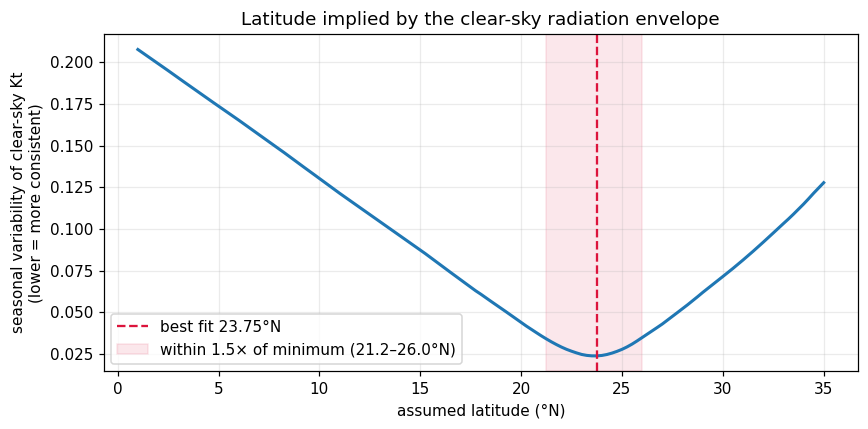

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profile["latitude_deg"], profile["objective_cv"], lw=2)
ax.axvline(latitude_estimate.latitude_deg, color="crimson", ls="--",
           label=f"best fit {latitude_estimate.latitude_deg:.2f}°N")
low, high = latitude_estimate.plausible_range_deg
ax.axvspan(low, high, color="crimson", alpha=0.10,
           label=f"within 1.5× of minimum ({low:.1f}–{high:.1f}°N)")
ax.set_xlabel("assumed latitude (°N)")
ax.set_ylabel("seasonal variability of clear-sky Kt\n(lower = more consistent)")
ax.set_title("Latitude implied by the clear-sky radiation envelope")
ax.legend()
fig.savefig(config.FIGURES_DIR / "site_latitude_profile.png", bbox_inches="tight")
plt.show()


### 6.2 · Independent evidence from the rainfall regime

The monthly rainfall climatology is a second, unrelated signal about the region.


,mean_monthly_rainfall_mm,share_of_annual_pct
month,,
1,0.8100,0.0900
2,0.0100,0.0000
3,4.1100,0.4700
4,3.3000,0.3800
5,8.3800,0.9600
6,111.6200,12.8100
7,267.2300,30.6700
8,265.9800,30.5300
9,179.4400,20.6000



mean annual rainfall       : 871 mm
June–September share       : 94.6%
October share              : 2.7%


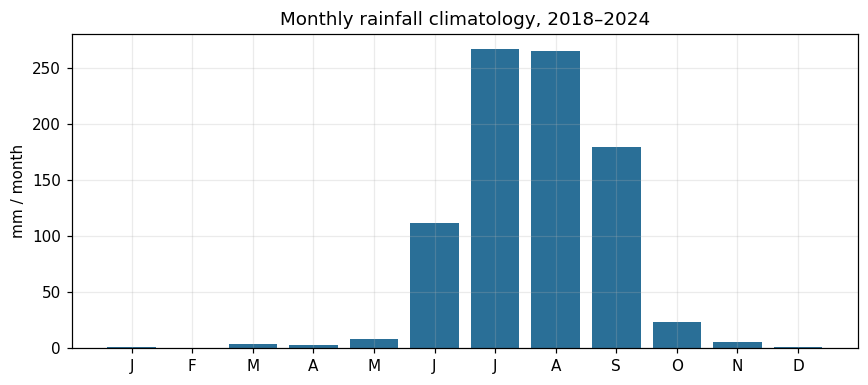

In [8]:
regime = site_inference.rainfall_regime(weather_in)
display(regime)

monsoon_share = regime.loc[[6, 7, 8, 9], "share_of_annual_pct"].sum()
annual_total = regime["mean_monthly_rainfall_mm"].sum()
print(f"\nmean annual rainfall       : {annual_total:,.0f} mm")
print(f"June–September share       : {monsoon_share:.1f}%")
print(f"October share              : {regime.loc[10, 'share_of_annual_pct']:.1f}%")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(regime.index, regime["mean_monthly_rainfall_mm"], color="#2a6f97")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("mm / month")
ax.set_title("Monthly rainfall climatology, 2018–2024")
fig.savefig(config.FIGURES_DIR / "rainfall_climatology.png", bbox_inches="tight")
plt.show()


**What this rules out.** The rain is overwhelmingly concentrated in June–September
with a nearly dry October. South-interior Karnataka has a markedly different
signature: a secondary September–October peak from the retreating monsoon. Taken
with the latitude estimate, the evidence does **not** support treating this
series as a Karnataka record.

That has a direct consequence for the rest of the study. The district rainfall
file and the Karnataka growth-stage reference must **not** be joined to this
weather series as if they described the same place. They are used only for what
they are: a regional context lookup and a source of agronomic constants.


### 6.3 · How much does the unresolved site actually matter?

This is the question that decides whether the study can proceed. Latitude and
elevation enter ET0 in a narrow way: latitude only through `Ra`, which affects
the clear-sky ceiling `Rso` and hence the cloudiness correction in net longwave
radiation; elevation only through barometric pressure and `Rso`. Measured solar
radiation carries the dominant energy term regardless of where the site is.

So rather than argue about it, recompute ET0 across the whole plausible envelope
and measure the spread.


In [9]:
site = config.load_site_config()
print(f"configured site : {site.latitude_deg}°N, {site.elevation_m} m")
print(f"status          : {site.resolution_status} (provisional = {site.is_provisional})")
print()

sensitivity = site_inference.et0_sensitivity(weather_in, site)
pivot = sensitivity.pivot(index="latitude_deg", columns="elevation_m",
                          values="mean_et0_mm_day")
display(pivot.round(4))

summary = site_inference.sensitivity_summary(sensitivity)
for key, value in summary.items():
    print(f"  {key:32s} {value:.4f}" if isinstance(value, float) else f"  {key:32s} {value}")


configured site : 23.7°N, 300.0 m
status          : inferred_from_data (provisional = True)



elevation_m,0.0000,500.0000,"1,000.0000"
latitude_deg,,,
11.5000,5.5937,5.5773,5.5612
13.7500,5.5771,5.5605,5.5443
16.0000,5.5573,5.5405,5.5241
18.2500,5.5341,5.5171,5.5004
20.5000,5.5071,5.4898,5.4729
22.7500,5.4759,5.4583,5.4410
25.0000,5.4409,5.4223,5.4044


  envelope_mean_et0_mm_day         5.5095
  envelope_min_et0_mm_day          5.4044
  envelope_max_et0_mm_day          5.5937
  half_spread_pct                  1.7178
  corners_evaluated                21


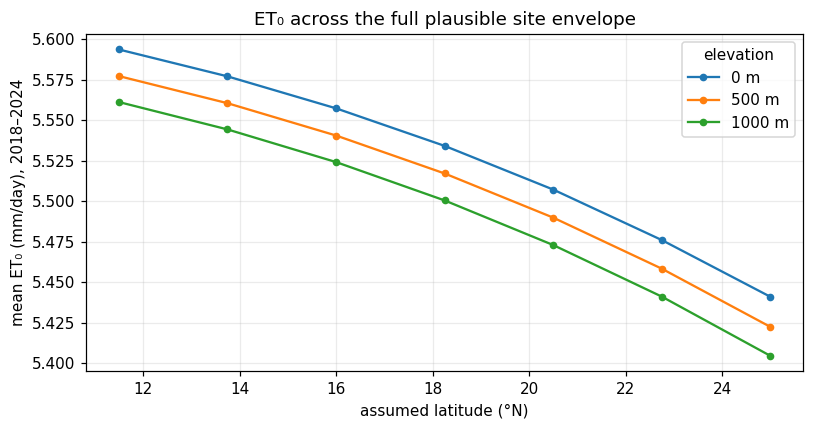

Across latitudes 11.5–25.0°N and elevations 0–1000 m, mean ET₀ moves by ±1.72% about the envelope mean.


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for elevation, group in sensitivity.groupby("elevation_m"):
    ax.plot(group["latitude_deg"], group["mean_et0_mm_day"],
            marker="o", ms=4, label=f"{elevation:.0f} m")
ax.set_xlabel("assumed latitude (°N)")
ax.set_ylabel("mean ET₀ (mm/day), 2018–2024")
ax.set_title("ET₀ across the full plausible site envelope")
ax.legend(title="elevation")
fig.savefig(config.FIGURES_DIR / "site_et0_sensitivity.png", bbox_inches="tight")
plt.show()

print(f"Across latitudes {site.latitude_envelope[0]}–{site.latitude_envelope[1]}°N and "
      f"elevations {site.elevation_envelope[0]:.0f}–{site.elevation_envelope[1]:.0f} m, "
      f"mean ET₀ moves by ±{summary['half_spread_pct']:.2f}% about the envelope mean.")


**Decision.** The site stays formally unresolved and every artefact carries that
status, but the study proceeds, because the consequence has been measured rather
than waved away: across the entire plausible envelope ET₀ moves by under two
percent, which is far smaller than the uncertainty in the crop coefficients that
multiply it. The configured coordinate lives in `config/site.yaml` alongside its
provenance and its caveats, and `ml/config.py` refuses to compute ET₀ at all if
that file is emptied out — `allow_provisional: false` turns the gate back on.


## 7 · Can `water_requirement_liters` be the ground truth?

`crop_water_data.csv` is the only file that offers something resembling a crop
water requirement target, so it has to be tested before it is trusted. Four
independent tests are applied, in `ml/target_audit.py`.

The tests are validated in both directions. `tests/test_target_audit.py` builds a
synthetic dataset that is physically coherent by construction and confirms the
audit **accepts** it. An audit that rejected everything would prove nothing; the
positive control is what gives the verdict below its force.


In [11]:
from ml import target_audit

crop_water = data_loader.load_dataset("crop_water")
audit = target_audit.audit_candidate_target(crop_water)
display(audit.to_frame())
print()
print(audit.rationale)


INFO    ml.data_loader           loaded crop_water             [cleaned]    10000 rows x 14 cols  <- crop_water_data_cleaned.csv


INFO    ml.target_audit          dimensional_consistency  FAIL: median implied depth is 0.004458 mm per record, about 112 times smaller than the lightest realistic irrigation application (0.5 mm); 0.00% of rows fall in the plausible range


INFO    ml.target_audit          driver_correlation       FAIL: the strongest correlation between the stated evapotranspiration and any of its physical drivers is |r| = 0.0131; a measured or physically modelled ET series cannot be uncorrelated with radiation, temperature, humidity and wind simultaneously


INFO    ml.target_audit          marginal_distribution    FAIL: 9 of 9 numeric columns are statistically indistinguishable from a uniform distribution over a round interval; measured agronomic variables are not uniform


INFO    ml.target_audit          generative_structure     FAIL: a log-linear model of the target on the other columns explains R2 = 0.896 of its variance, with exponents 1.22 on evapotranspiration and 1.05 on field area, and the values are clipped at both ends (474 rows at the minimum, 427 at the maximum)


WARNING ml.target_audit          verdict: usable_as_ground_truth = False


,test,verdict,finding
0,dimensional_consistency,FAIL,median implied depth is 0.004458 mm per record...
1,driver_correlation,FAIL,the strongest correlation between the stated e...
2,marginal_distribution,FAIL,9 of 9 numeric columns are statistically indis...
3,generative_structure,FAIL,a log-linear model of the target on the other ...



Rejected. The stated volume does not correspond to a physically possible irrigation depth once field area is taken into account, so the column cannot be an observed water requirement regardless of what the remaining tests show. Failing tests: dimensional_consistency, driver_correlation, marginal_distribution, generative_structure.


### 7.1 · Test 1 — does the volume correspond to a real water depth?

One millimetre of water over one hectare is 10,000 litres, so
    depth (mm) = litres / (hectares × 10,000)

  median implied depth : 0.004458 mm
  largest implied depth: 0.029638 mm
  a real irrigation event delivers roughly 0.5–150.0 mm
  rows inside that range: 0.00%


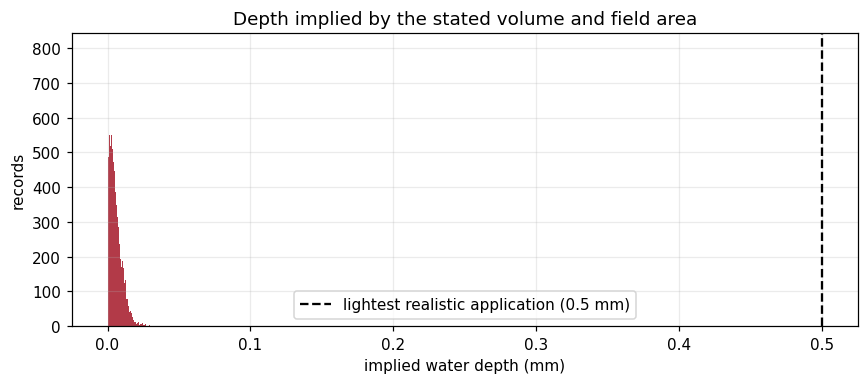

In [12]:
dimensional = audit.findings[0].evidence
implied_mm = crop_water["water_requirement_liters"] / (crop_water["field_area_ha"] * 10_000)

print("One millimetre of water over one hectare is 10,000 litres, so")
print("    depth (mm) = litres / (hectares × 10,000)\n")
print(f"  median implied depth : {dimensional['median_implied_depth_mm']:.6f} mm")
print(f"  largest implied depth: {dimensional['max_implied_depth_mm']:.6f} mm")
print(f"  a real irrigation event delivers roughly "
      f"{dimensional['plausible_range_mm'][0]}–{dimensional['plausible_range_mm'][1]} mm")
print(f"  rows inside that range: {dimensional['fraction_in_plausible_range']:.2%}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(implied_mm, bins=60, color="#b23a48")
ax.axvline(0.5, color="black", ls="--", label="lightest realistic application (0.5 mm)")
ax.set_xlabel("implied water depth (mm)")
ax.set_ylabel("records")
ax.set_title("Depth implied by the stated volume and field area")
ax.legend()
fig.savefig(config.FIGURES_DIR / "target_implied_depth.png", bbox_inches="tight")
plt.show()


Every record implies a depth of a few thousandths of a millimetre. Nothing in
irrigation practice produces that. Whatever this column measures, it is not a
volume of water applied to the stated area, and this test alone is decisive.


### 7.2 · Test 2 — does the evapotranspiration column respond to its own drivers?

,driver,pearson_r,p_value
0,temperature,-0.0107,0.2837
1,humidity,0.0131,0.1917
2,solar_radiation,-0.0069,0.4927
3,wind_speed_kmh,0.0063,0.5264


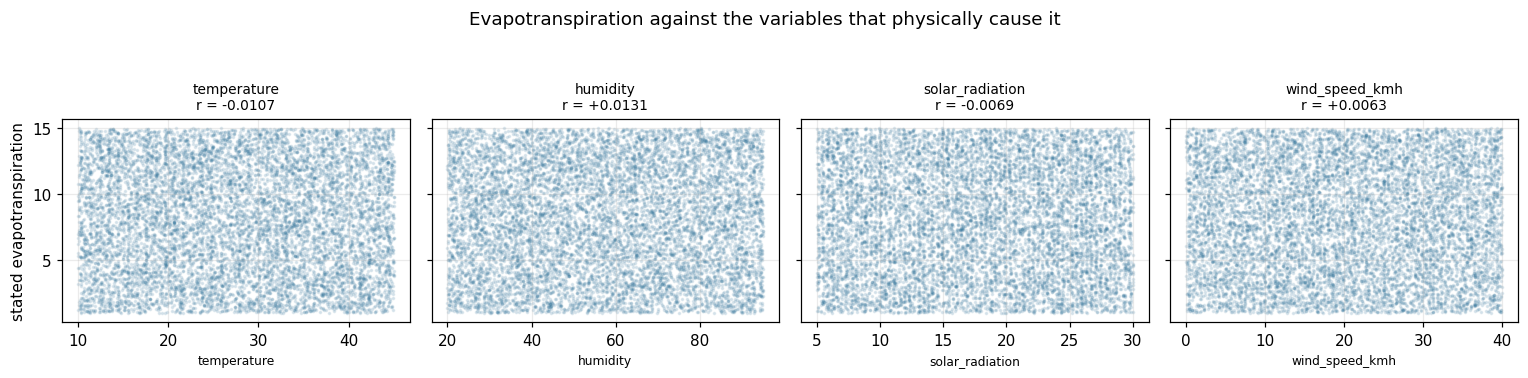

In [13]:
correlations = pd.DataFrame(audit.findings[1].evidence["correlations"])
display(correlations.round(4))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, driver in zip(axes, ["temperature", "humidity", "solar_radiation", "wind_speed_kmh"]):
    ax.scatter(crop_water[driver], crop_water["evapotranspiration"], s=2, alpha=0.12,
               color="#2a6f97")
    r = float(correlations.loc[correlations["driver"] == driver, "pearson_r"].iloc[0])
    ax.set_title(f"{driver}\nr = {r:+.4f}", fontsize=9)
    ax.set_xlabel(driver, fontsize=8)
axes[0].set_ylabel("stated evapotranspiration")
fig.suptitle("Evapotranspiration against the variables that physically cause it", y=1.06)
fig.savefig(config.FIGURES_DIR / "target_et_drivers.png", bbox_inches="tight")
plt.show()


Evapotranspiration is driven by radiation, temperature, humidity and wind. Here
it is uncorrelated with all four simultaneously. A measured — or even a
physically modelled — ET series cannot look like this.


### 7.3 · Test 3 — are the marginals just uniform draws?

In [14]:
uniformity = pd.DataFrame(audit.findings[2].evidence["tests"])
display(uniformity.round(4))
print(f"\n{audit.findings[2].evidence['n_uniform']} of {len(uniformity)} columns are "
      "statistically indistinguishable from a uniform distribution "
      "over a round interval.")


,column,min,max,ks_statistic,p_value,uniform_not_rejected
0,temperature,10.0000,45.0000,0.0074,0.6436,True
1,humidity,20.0000,95.0000,0.0073,0.6525,True
2,rainfall_mm,0.0000,50.0000,0.0069,0.7251,True
3,wind_speed_kmh,0.0000,40.0000,0.0086,0.4478,True
4,solar_radiation,5.0000,30.0000,0.0093,0.3505,True
5,field_area_ha,0.5100,49.9900,0.0070,0.7081,True
6,crop_age_days,1.0000,179.0000,0.0128,0.0745,True
7,soil_moisture_pct,10.0000,60.0000,0.0110,0.1764,True
8,evapotranspiration,1.0000,15.0000,0.0084,0.4847,True



9 of 9 columns are statistically indistinguishable from a uniform distribution over a round interval.


### 7.4 · Test 4 — can the generating formula be recovered?

In [15]:
generative = audit.findings[3].evidence
print(f"log-linear fit R²          : {generative['r_squared']:.4f}")
print(f"exponent on ET             : {generative['exponent_on_et']:.3f}")
print(f"exponent on field area     : {generative['exponent_on_area']:.3f}")
print(f"residual sd (log scale)    : {generative['residual_sd_log']:.3f}")
print(f"rows pinned at the minimum : {generative['rows_at_floor']} "
      f"(value {generative['floor_value']:g})")
print(f"rows pinned at the maximum : {generative['rows_at_ceiling']} "
      f"(value {generative['ceiling_value']:g})")
print("\nimplied per-category multipliers:")
for column, levels in generative["category_multipliers"].items():
    formatted = ", ".join(f"{k} ×{v:.2f}" for k, v in sorted(levels.items()))
    print(f"  {column:20s} {formatted}")


log-linear fit R²          : 0.8962
exponent on ET             : 1.220
exponent on field area     : 1.046
residual sd (log scale)    : 0.412
rows pinned at the minimum : 474 (value 1)
rows pinned at the maximum : 427 (value 5000)

implied per-category multipliers:
  crop_type            Maize ×0.85, Potato ×0.51, Rice ×1.19, Soybean ×0.67, Sugarcane ×1.52, Wheat ×0.66
  growth_stage         Fruiting ×1.11, Germination ×0.35, Maturity ×0.53, Vegetative ×0.61
  soil_type            Loamy ×0.79, Peaty ×0.70, Sandy ×0.60, Silty ×0.89
  irrigation_method    Flood ×1.66, Furrow ×1.40, Sprinkler ×1.19


### 7.5 · Verdict and what the study does instead

The column behaves like a generated quantity: multiplicative in evapotranspiration
and area, scaled by a fixed multiplier per crop, stage, soil and irrigation
method, with lognormal noise, clipped to a round interval at both ends.

**`water_requirement_liters` is rejected as ground truth.** The dataset is kept
in the repository as a documented negative control — it is genuinely useful for
showing what a model trained on an invalid target looks like — but it does not
enter the research path.

That leaves the study without independently observed crop water requirement,
which is a real limitation and is recorded as one. The next phase therefore
defines the supervised target explicitly as a **FAO-56 reference-derived crop
evapotranspiration**, computed from the real weather series and the
growth-stage crop coefficients. The model learns and refines a reference-derived
quantity; it does not predict field-observed water use, and the write-up says so
in those words.


## 8 · Cleaning, imputation, validation and feature engineering

`ml/preprocessing.py` runs the whole sequence. Each step logs what it did, and
the log is displayed below rather than summarised, so nothing happens silently.

The one real gap — a single day of missing shortwave radiation — is filled from
that day's temperature range using FAO-56 equation 50, the substitution FAO-56
itself prescribes when measured radiation is unavailable. Two alternatives are
computed alongside it so the choice can be compared rather than asserted.


In [16]:
from ml.preprocessing import run_preprocessing

result = run_preprocessing(latitude_for_imputation=site.latitude_deg)


INFO    ml.data_loader           loaded climate                [raw]         2557 rows x 11 cols  <- Climate_Data.csv


INFO    ml.data_loader           loaded climate                [cleaned]     2557 rows x 11 cols  <- Climate_Data_cleaned.csv


INFO    ml.data_cleaner          climate | replace_sentinels: no sentinel values found


INFO    ml.data_cleaner          climate | parse_dates: parsed datetime; 0 value(s) unparseable


INFO    ml.data_cleaner          climate | sort: ordered chronologically by datetime


...

INFO    ml.preprocessing         wrote district_rainfall_normals.parquet (29 rows x 8 cols)


INFO    ml.preprocessing         wrote crop_suitability_samples.parquet (2200 rows x 8 cols)


INFO    ml.preprocessing         wrote season_context.parquet (3158 rows x 10 cols)


INFO    ml.lineage               lineage for 28 feature(s) written to feature_lineage.csv


INFO    ml.preprocessing         wrote preprocessing_metadata.json


In [17]:
print("CLEANING STEPS APPLIED\n")
display(result.cleaning_log[["dataset", "step", "detail", "rows_before", "rows_after"]])


CLEANING STEPS APPLIED



,dataset,step,detail,rows_before,rows_after
0,climate,replace_sentinels,no sentinel values found,2557,2557
1,climate,parse_dates,parsed datetime; 0 value(s) unparseable,2557,2557
2,climate,sort,ordered chronologically by datetime,2557,2557
3,climate,drop_redundant_date_parts,"dropped ['date', 'month', 'year']; they duplic...",2557,2557
4,climate,temperature_ordering,0 day(s) had Tmin above Tmax and were voided,2557,2557
5,climate,range_guard[rh2m],0 value(s) outside the physical range were voided,2557,2557
6,climate,range_guard[ws2m],0 value(s) outside the physical range were voided,2557,2557
7,climate,range_guard[prectotcorr],0 value(s) outside the physical range were voided,2557,2557
8,climate,feature_engineering,added temporal and rolling features (windows: ...,2557,2557
9,soil,strip_text_columns,no whitespace to trim,875,875


In [18]:
print("IMPUTATION\n")
for record in result.imputations:
    print(f"  column   : {record.column}")
    print(f"  method   : {record.method}")
    print(f"  dates    : {record.indices}")
    print(f"  value    : {record.filled_values[0]:.4f} MJ/m²/day")
    print(f"  rationale: {record.justification}\n")
    print("  what each candidate method would have produced:")
    for method, value in record.comparison.items():
        print(f"    {method:28s} {value:8.4f}")

if not result.imputations:
    print("  nothing required imputation")


IMPUTATION

  column   : allsky_sfc_sw_dwn
  method   : fao56_temperature_range
  dates    : ['2024-12-04']
  value    : 15.5152 MJ/m²/day
  rationale: FAO-56 equation 50 estimates shortwave radiation from the daily temperature range when measured radiation is unavailable. It is preferred over interpolation here because it uses same-day observations rather than borrowing from adjacent days, and because it is the substitution FAO-56 itself prescribes.

  what each candidate method would have produced:
    fao56_temperature_range       15.5152
    linear_interpolation          15.4950
    seasonal_normal               14.5871


The physics-based fill and simple interpolation land within a fraction of a
percent of each other. Two unrelated methods agreeing is reasonable evidence that
the filled value is sound, and the `allsky_sfc_sw_dwn_was_imputed` flag travels
with the data so any downstream result can be recomputed with that day excluded.


In [19]:
print("VALIDATION\n")
summary = result.validation.summary()
print(f"  checks run : {summary['checks_run']}")
print(f"  passed     : {summary['passed']}")
print(f"  errors     : {summary['errors']}")
print(f"  warnings   : {summary['warnings']}\n")
display(result.validation.to_frame())

failures = result.validation.failures_frame()
if failures.empty:
    print("\nNo check failed.")
else:
    display(failures)

result.validation.raise_if_errors()


VALIDATION

  checks run : 35
  passed     : 35
  errors     : 0
  warnings   : 0



,dataset,check,status,severity,message
0,climate,columns_present,PASS,error,all expected columns present
1,climate,date_continuity[datetime],PASS,error,"2557 daily records, 2018-01-01 to 2024-12-31, ..."
2,climate,unique_key[datetime],PASS,error,key is unique
3,climate,sentinel_values,PASS,error,no sentinel values remain
4,climate,ordering[t2m_min<=t2m_max],PASS,error,t2m_min <= t2m_max holds everywhere
5,climate,ordering[t2m_min<=t2m],PASS,error,t2m_min <= t2m holds everywhere
6,climate,ordering[t2m<=t2m_max],PASS,error,t2m <= t2m_max holds everywhere
7,climate,range[t2m],PASS,error,"t2m within [-40.0, 60.0]"
8,climate,range[t2m_min],PASS,error,"t2m_min within [-50.0, 50.0]"
9,climate,range[t2m_max],PASS,error,"t2m_max within [-30.0, 60.0]"



No check failed.


## 9 · Feature lineage

Every column the pipeline produces is registered with its source file, its
source columns, the transformation applied and its unit. The `provenance_class`
is what the leakage review keys on later:

- `raw` — straight from a source file
- `derived` — computed from raw inputs, never involving the target
- `reference` — an agronomic constant from a reference table
- `reference_derived` — computed from the physics baseline, and therefore
  algebraically related to the eventual target

Nothing produced in this notebook is `reference_derived`, because ET₀, Kc and the
target belong to the next phase. That is deliberate: it makes every feature here
independent of the target *by construction*, which is a stronger guarantee than
checking for leakage after the fact.


In [20]:
lineage_table = result.lineage.to_frame()
display(lineage_table)

print("\nfeatures per provenance class:")
print(lineage_table["provenance_class"].value_counts().to_string())

coverage = result.lineage.coverage_report(result.weather.columns)
unregistered = coverage[coverage["status"] == "UNREGISTERED"]
print(f"\ncolumns produced without lineage: {len(unregistered)}")
if not unregistered.empty:
    display(unregistered)


,feature,provenance_class,source_dataset,source_columns,transformation,unit,notes
0,allsky_sfc_sw_dwn,raw,Climate_Data.csv,ALLSKY_SFC_SW_DWN,renamed to snake_case; sentinel values convert...,MJ/m2/day,all-sky downward shortwave irradiance; one day...
1,datetime,raw,Climate_Data.csv,datetime,parsed to a datetime and sorted ascending,date,"daily, complete, no gaps or repeats"
2,prectotcorr,raw,Climate_Data.csv,PRECTOTCORR,renamed to snake_case; sentinel values convert...,mm/day,bias-corrected total precipitation
3,rh2m,raw,Climate_Data.csv,RH2M,renamed to snake_case; sentinel values convert...,%,"2 m relative humidity, daily mean"
4,t2m,raw,Climate_Data.csv,T2M,renamed to snake_case; sentinel values convert...,degC,"2 m air temperature, daily mean"
5,t2m_max,raw,Climate_Data.csv,T2M_MAX,renamed to snake_case; sentinel values convert...,degC,"2 m air temperature, daily maximum"
6,t2m_min,raw,Climate_Data.csv,T2M_MIN,renamed to snake_case; sentinel values convert...,degC,"2 m air temperature, daily minimum"
7,ws2m,raw,Climate_Data.csv,WS2M,renamed to snake_case; sentinel values convert...,m/s,2 m wind speed; already at the FAO-56 referenc...
8,allsky_sfc_sw_dwn_was_imputed,derived,Climate_Data.csv,ALLSKY_SFC_SW_DWN,flag marking days whose radiation was filled b...,0/1,lets any result be recomputed with imputed day...
9,day_of_year,derived,Climate_Data.csv,datetime,ordinal day of the observation,1-366,



features per provenance class:
provenance_class
derived    20
raw         8

columns produced without lineage: 0


## 10 · Growth-stage crop coefficients

The study needs Kc as a function of crop and days since sowing. Two files
contribute and they are shaped very differently: the crop calendar is already
numeric, while the Karnataka reference states coefficients and timings as
English sentences with ranges and citations.

The numbers are extracted mechanically, but *choosing* between competing values
and reconciling overlapping stage windows are judgement calls, so those live in
`config/crop_stages.yaml` with the reasoning written next to each decision
rather than buried in code.


In [21]:
from ml.crop_reference import CropCoefficientModel, parse_reference_kc_table

growth_reference = data_loader.load_dataset("growth_stage_reference")
print("Kc values extracted from the free-text reference cells:\n")
display(parse_reference_kc_table(growth_reference)[
    ["source_crop", "source_stage", "kc_type", "kc_text", "kc_candidates"]
])


INFO    ml.data_loader           loaded growth_stage_reference [cleaned]       13 rows x  7 cols  <- Karnataka_Crop_Growth_Stage_Reference_cleaned.csv


Kc values extracted from the free-text reference cells:



,source_crop,source_stage,kc_type,kc_text,kc_candidates
0,Paddy (Rice),Initial / Establishment,Kc_ini,Wet paddy Kc_ini = 1.05–1.10; local Hemavathy ...,"[1.05, 1.1]"
1,Paddy (Rice),Development / Tillering,Interpolated,Kc curve from initial toward mid-season,[]
2,Paddy (Rice),Mid-Season / Flowering,Kc_mid,Wet paddy Kc_mid = 1.20,[1.2]
3,Paddy (Rice),Late-Season / Maturity,Kc_end,Wet paddy Kc_end = 1.05,[1.05]
4,Paddy (Rice),Harvest,Terminal,Terminal reference; harvest timing is variety-...,[]
5,Finger Millet (Ragi),Initial / Establishment,Kc_ini,Local Hemavathy study Kc_ini = 0.30,[0.3]
6,Finger Millet (Ragi),Development / Vegetative,Interpolated,Interpolate from Kc_ini toward Kc_mid,[]
7,Finger Millet (Ragi),Mid-Season / Flowering,Kc_mid / peak,Local Kc_mid = 1.00; Bangalore study peak ≈1.0...,"[1.0, 1.02]"
8,Finger Millet (Ragi),Late-Season / Grain Development & Maturity,Kc_end,Local Kc_end = 0.30,[0.3]
9,Maize,Initial / Establishment,Kc_ini,Local Kc_ini = 0.30,[0.3]


In [22]:
crop_calendar = data_loader.load_dataset("crop_calendar")
kc_model = CropCoefficientModel.from_sources(crop_calendar)

stage_table = kc_model.to_frame()
display(stage_table)

stage_table.to_csv(config.PROCESSED_DIR / "crop_stage_reference.csv",
                   index=False, encoding="utf-8")
print(f"\n{len(kc_model.crops)} crops with a complete four-stage Kc curve: "
      f"{', '.join(kc_model.crops)}")


INFO    ml.data_loader           loaded crop_calendar          [cleaned]       25 rows x  9 cols  <- Crop_Calender_cleaned.csv


INFO    ml.crop_reference        crop coefficient model covers 8 crops: chickpea, cotton, cumin, finger_millet, groundnut, maize, paddy, wheat


,crop,display_name,stage,stage_order,start_day,end_day,duration_days,kc_anchor,alternative_kc,kc_basis,source
0,chickpea,Chickpea,initial,0,0,25,25,0.4000,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
1,chickpea,Chickpea,development,1,25,55,30,NaN,0.7000,interpolated,Crop_Calender_cleaned.csv
2,chickpea,Chickpea,mid_season,2,55,95,40,1.0500,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
3,chickpea,Chickpea,late_season,3,95,115,20,0.5500,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
4,cotton,Cotton,initial,0,0,30,30,0.4500,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
5,cotton,Cotton,development,1,30,80,50,NaN,0.7500,interpolated,Crop_Calender_cleaned.csv
6,cotton,Cotton,mid_season,2,80,140,60,1.1500,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
7,cotton,Cotton,late_season,3,140,195,55,0.8500,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
8,cumin,Cumin,initial,0,0,25,25,0.3000,NaN,tabulated in Crop_Calender_cleaned.csv,Crop_Calender_cleaned.csv
9,cumin,Cumin,development,1,25,50,25,NaN,0.5000,interpolated,Crop_Calender_cleaned.csv



8 crops with a complete four-stage Kc curve: chickpea, cotton, cumin, finger_millet, groundnut, maize, paddy, wheat


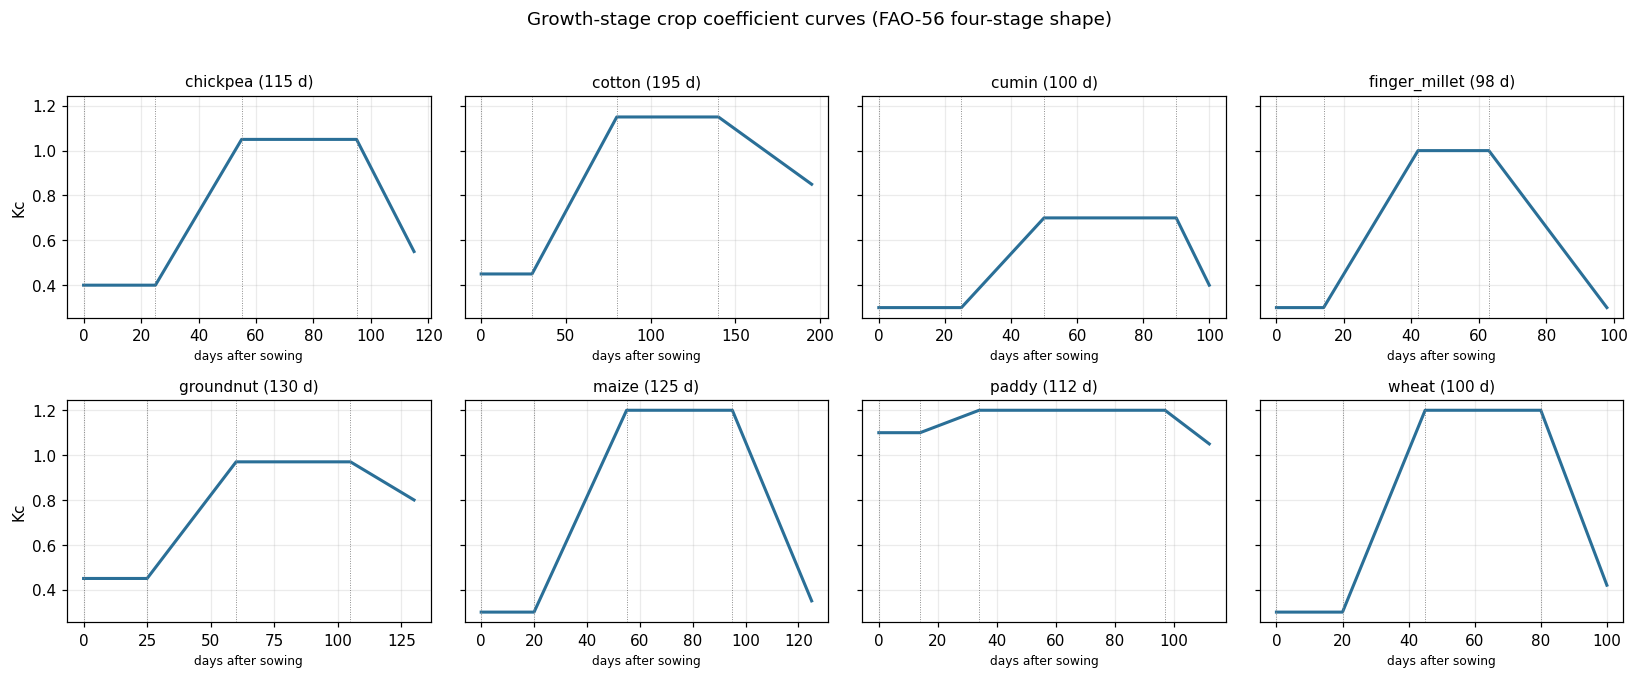

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, crop in zip(axes.ravel(), kc_model.crops):
    curve = kc_model.curve(crop)
    ax.plot(curve["days_after_sowing"], curve["kc"], lw=2, color="#2a6f97")
    for _, row in stage_table[stage_table["crop"] == crop].iterrows():
        ax.axvline(row["start_day"], color="grey", lw=0.6, ls=":")
    ax.set_title(f"{crop} ({kc_model.cycle_length(crop)} d)", fontsize=10)
    ax.set_xlabel("days after sowing", fontsize=8)
axes[0, 0].set_ylabel("Kc")
axes[1, 0].set_ylabel("Kc")
fig.suptitle("Growth-stage crop coefficient curves (FAO-56 four-stage shape)", y=1.02)
fig.savefig(config.FIGURES_DIR / "kc_curves.png", bbox_inches="tight")
plt.show()


Kc is flat through the initial stage, ramps linearly to the mid-season value
across development, holds through mid-season and ramps to the end-of-season value
across the late stage. Because development and late-season values are
interpolated rather than tabulated, a crop with a 40-day development stage
produces 40 distinct coefficients. That is what makes the resulting water
requirement genuinely stage-aware instead of a four-level step function.


## 11 · The prepared weather series

In [24]:
weather = result.weather
print(f"{len(weather):,} daily records × {weather.shape[1]} columns")
print(f"{pd.to_datetime(weather['datetime']).min().date()} → "
      f"{pd.to_datetime(weather['datetime']).max().date()}")
print(f"missing values: {int(weather.isna().sum().sum())}")
display(weather.head())
display(weather[["t2m", "t2m_min", "t2m_max", "rh2m", "ws2m",
                 "prectotcorr", "allsky_sfc_sw_dwn"]].describe().T)


2,557 daily records × 28 columns
2018-01-01 → 2024-12-31
missing values: 0


,datetime,t2m,t2m_min,t2m_max,rh2m,ws2m,prectotcorr,allsky_sfc_sw_dwn,allsky_sfc_sw_dwn_was_imputed,year,month,day_of_year,doy_sin,doy_cos,month_sin,month_cos,temp_range_c,temp_midrange_c,is_rain_day,rain_sum_7d_mm,rain_days_7d,temp_mean_7d_c,rh_mean_7d_pct,rain_sum_30d_mm,rain_days_30d,temp_mean_30d_c,rh_mean_30d_pct,days_since_rain
0,2018-01-01,17.9200,9.9600,27.9500,24.2300,2.4300,0.0000,16.9500,False,2018,1,1,0.0172,0.9999,0.0000,1.0000,17.9900,18.9550,0,0.0000,0.0000,17.9200,24.2300,0.0000,0.0000,17.9200,24.2300,1.0000
1,2018-01-02,18.2400,9.3400,28.7300,28.3200,2.1900,0.0000,15.6300,False,2018,1,2,0.0344,0.9994,0.0000,1.0000,19.3900,19.0350,0,0.0000,0.0000,18.0800,26.2750,0.0000,0.0000,18.0800,26.2750,2.0000
2,2018-01-03,19.3100,11.2800,29.7000,28.2100,1.8100,0.0000,15.3500,False,2018,1,3,0.0516,0.9987,0.0000,1.0000,18.4200,20.4900,0,0.0000,0.0000,18.4900,26.9200,0.0000,0.0000,18.4900,26.9200,3.0000
3,2018-01-04,19.2000,12.7500,28.9600,33.3700,1.6600,0.0000,15.6800,False,2018,1,4,0.0688,0.9976,0.0000,1.0000,16.2100,20.8550,0,0.0000,0.0000,18.6675,28.5325,0.0000,0.0000,18.6675,28.5325,4.0000
4,2018-01-05,19.9100,13.2100,28.7000,62.9000,1.4500,0.0000,16.1300,False,2018,1,5,0.0859,0.9963,0.0000,1.0000,15.4900,20.9550,0,0.0000,0.0000,18.9160,35.4060,0.0000,0.0000,18.9160,35.4060,5.0000


,count,mean,std,min,25%,50%,75%,max
t2m,"2,557.0000",26.6209,4.6134,13.4900,23.4400,27.4700,30.0900,36.7000
t2m_min,"2,557.0000",20.9044,5.6190,5.9500,16.6100,22.6200,25.5000,29.4700
t2m_max,"2,557.0000",33.7245,4.5205,21.4400,30.5900,32.7600,37.2800,45.1800
rh2m,"2,557.0000",58.8944,19.0811,14.7900,46.0100,57.7000,75.9600,94.5100
ws2m,"2,557.0000",3.0907,1.4430,0.5200,1.9800,2.7300,3.9900,12.2500
prectotcorr,"2,557.0000",2.3851,9.3835,0.0000,0.0000,0.0000,0.3000,174.2600
allsky_sfc_sw_dwn,"2,557.0000",18.9847,4.8711,1.5800,15.8100,18.6800,22.6400,28.9200


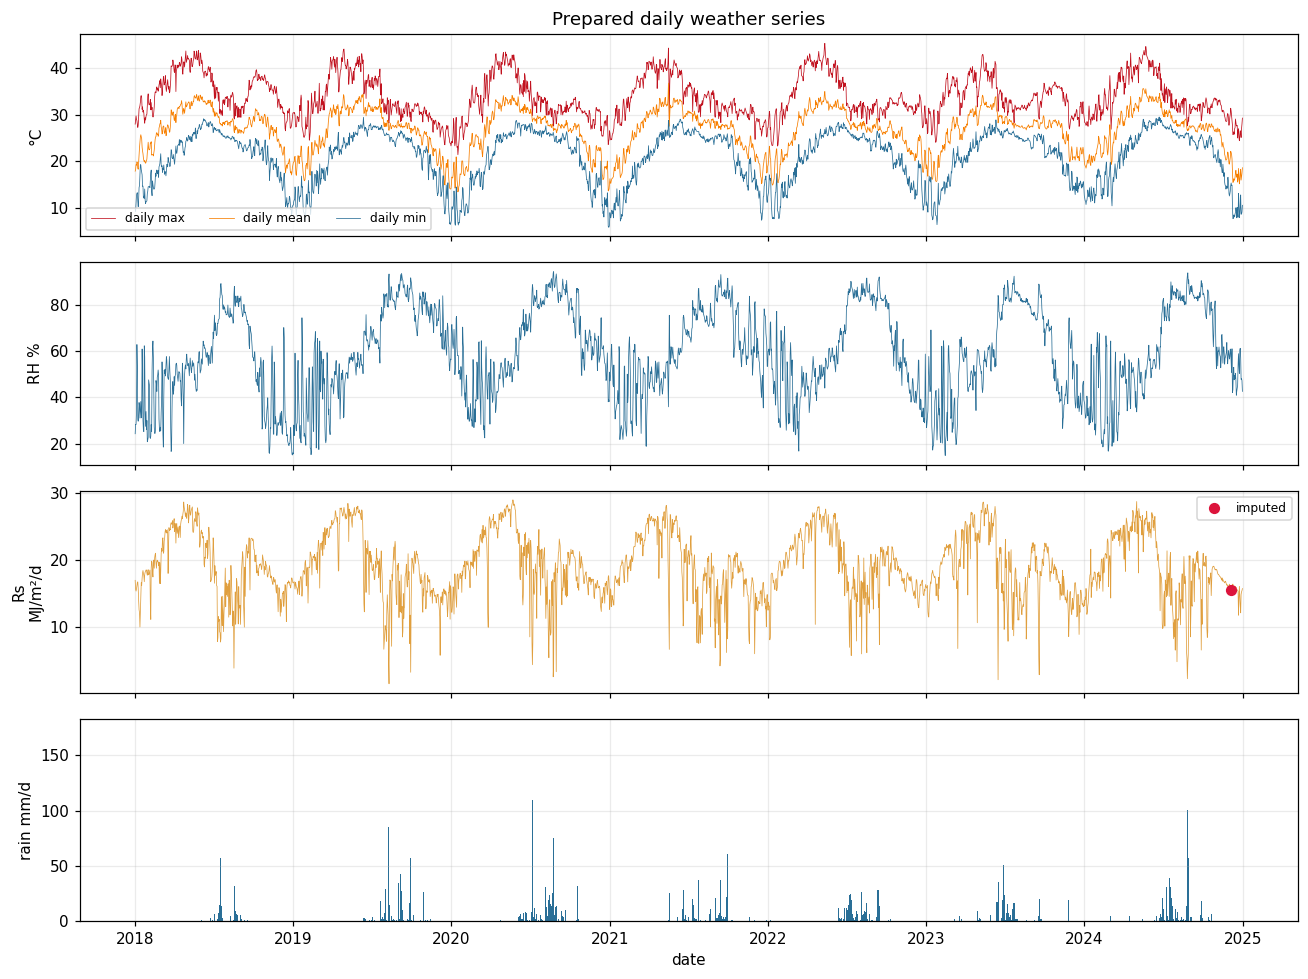

In [25]:
dates = pd.to_datetime(weather["datetime"])
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(dates, weather["t2m_max"], lw=0.5, color="#c1121f", label="daily max")
axes[0].plot(dates, weather["t2m"], lw=0.5, color="#f77f00", label="daily mean")
axes[0].plot(dates, weather["t2m_min"], lw=0.5, color="#2a6f97", label="daily min")
axes[0].set_ylabel("°C"); axes[0].legend(ncol=3, fontsize=8)
axes[0].set_title("Prepared daily weather series")

axes[1].plot(dates, weather["rh2m"], lw=0.5, color="#2a6f97")
axes[1].set_ylabel("RH %")

axes[2].plot(dates, weather["allsky_sfc_sw_dwn"], lw=0.5, color="#e09f3e")
imputed = weather["allsky_sfc_sw_dwn_was_imputed"].astype(bool)
axes[2].scatter(dates[imputed], weather.loc[imputed, "allsky_sfc_sw_dwn"],
                color="crimson", zorder=5, s=40, label="imputed")
axes[2].set_ylabel("Rs\nMJ/m²/d"); axes[2].legend(fontsize=8)

axes[3].bar(dates, weather["prectotcorr"], width=1.0, color="#2a6f97")
axes[3].set_ylabel("rain mm/d"); axes[3].set_xlabel("date")

fig.savefig(config.FIGURES_DIR / "weather_series.png", bbox_inches="tight")
plt.show()


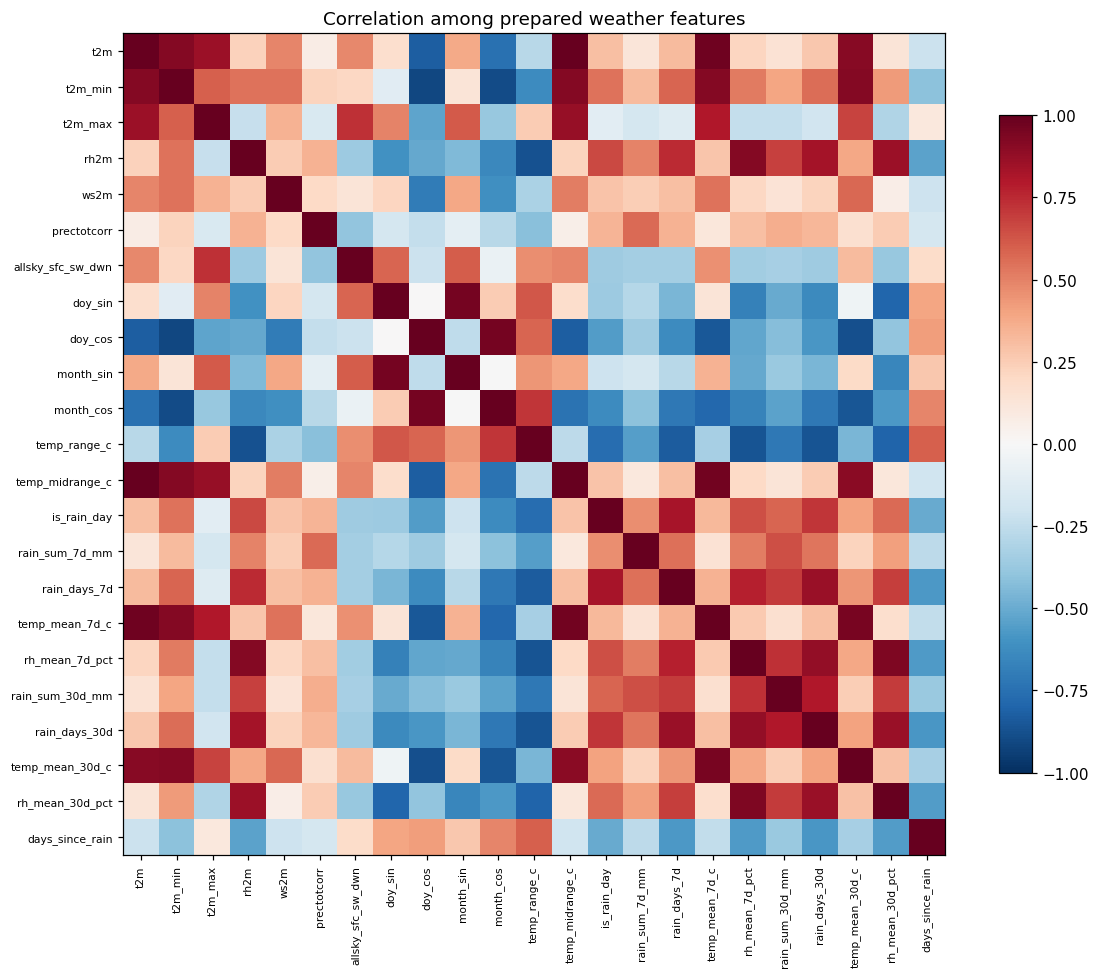

In [26]:
numeric = weather.select_dtypes("number").drop(columns=["year", "month", "day_of_year"],
                                               errors="ignore")
correlation = numeric.corr()
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)))
ax.set_xticklabels(correlation.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(correlation)))
ax.set_yticklabels(correlation.columns, fontsize=7)
ax.set_title("Correlation among prepared weather features")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8)
fig.savefig(config.FIGURES_DIR / "weather_correlation.png", bbox_inches="tight")
plt.show()


## 12 · Supporting tables

These are prepared and stored, but their role is limited. The soil and district
rainfall files describe Indian districts with no established spatial link to the
weather series, so they are context lookups, not modelling inputs joined by
location. Section 6 is the reason that restriction exists.


In [27]:
print(f"SOIL — {len(result.soil)} samples across "
      f"{result.soil['district'].nunique()} districts")
display(result.soil.describe().T)

print(f"\nDISTRICT RAINFALL NORMALS — {len(result.district_rainfall)} districts")
display(result.district_rainfall[["district", "normal_rainy_days",
                                  "normal_annual_rainfall_mm"]].head(10))

print(f"\nCROP SUITABILITY — {len(result.crop_suitability)} samples, "
      f"{result.crop_suitability['label'].nunique()} crops")
display(result.crop_suitability["label"].value_counts().head(10).to_frame("samples"))


SOIL — 875 samples across 101 districts


,count,mean,std,min,25%,50%,75%,max
nitrogen,875.0000,24.7697,8.7039,20.0000,20.0315,20.2670,25.0550,66.9590
phosphorus,875.0000,61.1565,13.5046,20.0450,50.1395,61.8900,73.9550,80.0000
potassium,875.0000,61.7400,12.9610,22.9100,52.7130,63.2600,72.2900,80.0000
ph,875.0000,7.0745,0.2830,6.0503,6.9991,7.0060,7.0922,9.0310



DISTRICT RAINFALL NORMALS — 29 districts


,district,normal_rainy_days,normal_annual_rainfall_mm
0,BENGALURU(R),45,751
1,RAMANAGARA,43,822
2,CHITRADURGA,40,507
3,DAVANAGERE,56,637
4,KOLAR,35,622
5,CHIKKABALLAPURA,92,677
6,SHIVAMOGGA,99,2682
7,TUMAKURU,36,589
8,CHIKKAMAGALURU,92,2075
9,DAKSHINA KANNADA,127,3524



CROP SUITABILITY — 2200 samples, 22 crops


,samples
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


## 13 · Write the evidence out

In [28]:
quality_report.save_table(registry, "dataset_registry")
quality_report.save_table(fingerprints_before, "raw_file_fingerprints")
quality_report.save_table(raw_vs_cleaned, "raw_versus_cleaned_audit")
quality_report.save_table(result.profiles, "column_profiles")
quality_report.save_table(result.validation.to_frame(), "validation_results")
quality_report.save_table(result.missing_summary, "missing_values")
quality_report.save_table(result.cleaning_log, "cleaning_log")
quality_report.save_table(audit.to_frame(), "candidate_target_audit")
quality_report.save_table(lineage_table, "feature_lineage")
quality_report.save_table(stage_table, "crop_stage_reference")
quality_report.save_table(sensitivity, "site_et0_sensitivity")
quality_report.save_table(latitude_estimate.profile, "site_latitude_profile")
quality_report.save_table(regime.reset_index(), "rainfall_climatology")

result.validation.save_json(config.QUALITY_DIR / "validation_report.json")
quality_report.save_json(audit.to_dict(), "candidate_target_audit")

site_summary = {
    **site.as_metadata(),
    "latitude_estimate_from_data_deg": latitude_estimate.latitude_deg,
    "latitude_estimate_resample_sd_deg": latitude_estimate.resample_sd_deg,
    "latitude_plausible_range_deg": list(latitude_estimate.plausible_range_deg),
    "implied_clear_sky_kt": latitude_estimate.clear_sky_kt,
    "et0_sensitivity": site_inference.sensitivity_summary(sensitivity),
    "mean_annual_rainfall_mm": float(regime["mean_monthly_rainfall_mm"].sum()),
    "june_to_september_share_pct": float(regime.loc[[6, 7, 8, 9], "share_of_annual_pct"].sum()),
}
quality_report.save_json(site_summary, "site_resolution")


INFO    ml.quality_report        wrote dataset_registry.csv (9 rows)


INFO    ml.quality_report        wrote raw_file_fingerprints.csv (9 rows)


INFO    ml.quality_report        wrote raw_versus_cleaned_audit.csv (25 rows)


INFO    ml.quality_report        wrote column_profiles.csv (60 rows)


INFO    ml.quality_report        wrote validation_results.csv (35 rows)


...

INFO    ml.quality_report        wrote rainfall_climatology.csv (12 rows)


INFO    ml.data_validator        validation report written to validation_report.json


INFO    ml.quality_report        wrote candidate_target_audit.json


INFO    ml.quality_report        wrote site_resolution.json


WindowsPath('D:/Projects/JALACHAKRA/AgriHydro/reports/data_quality/site_resolution.json')

In [29]:
report_path = quality_report.write_markdown_report(
    path=config.QUALITY_DIR / "data_quality_report.md",
    run_timestamp=RUN_TIMESTAMP,
    registry=registry,
    fingerprints=fingerprints_before,
    profiles=result.profiles,
    validation=result.validation.to_frame(),
    validation_summary=result.validation.summary(),
    missing=result.missing_summary,
    cleaning=result.cleaning_log,
    raw_vs_cleaned=raw_vs_cleaned,
    target_audit=audit.to_frame(),
    target_rationale=audit.rationale,
    site_summary=site_summary,
    lineage=lineage_table,
)
print(f"report written to {report_path.relative_to(PROJECT_ROOT)}")


INFO    ml.quality_report        data quality report written to D:\Projects\JALACHAKRA\AgriHydro\reports\data_quality\data_quality_report.md


report written to reports\data_quality\data_quality_report.md


## 14 · Confirm the raw files were not touched

In [30]:
fingerprints_after = data_loader.raw_fingerprint()
identical = fingerprints_before.equals(fingerprints_after)
print(f"raw files unchanged by this notebook: {identical}")
if not identical:
    display(fingerprints_before.compare(fingerprints_after))
assert identical, "a raw file changed during this run"


raw files unchanged by this notebook: True


## 15 · What this notebook established

In [31]:
weather_start = pd.to_datetime(weather["datetime"]).min().date()
weather_end = pd.to_datetime(weather["datetime"]).max().date()

print(f"""
FINDINGS
--------
1. Weather series: {len(weather):,} complete daily records, {weather_start} to {weather_end},
   no gaps, no duplicate dates, no remaining sentinel values. One day of solar
   radiation was imputed from the temperature range using FAO-56 eq. 50 and is
   flagged in the data.

2. Site: latitude estimated at {latitude_estimate.latitude_deg:.2f}°N from the clear-sky
   radiation envelope (leave-one-year-out sd {latitude_estimate.resample_sd_deg:.2f}°), but the
   estimator is biased upward by seasonal haze, so provenance stays UNRESOLVED.
   The consequence was measured instead of assumed: across latitudes
   {site.latitude_envelope[0]}–{site.latitude_envelope[1]}°N and elevations
   {site.elevation_envelope[0]:.0f}–{site.elevation_envelope[1]:.0f} m, mean ET0 varies by only
   ±{site_summary['et0_sensitivity']['half_spread_pct']:.2f}%.

3. The rainfall regime ({site_summary['june_to_september_share_pct']:.0f}% of
   {site_summary['mean_annual_rainfall_mm']:,.0f} mm falls in June–September, October nearly dry)
   is inconsistent with south-interior Karnataka. The district rainfall and
   Karnataka growth-stage files are therefore NOT joined to the weather series
   by location.

4. water_requirement_liters is REJECTED as ground truth. It fails all four
   audit tests; decisively, the implied irrigation depth is
   {dimensional['median_implied_depth_mm']:.6f} mm, about {0.5 / dimensional['median_implied_depth_mm']:,.0f}x
   smaller than the lightest real application. The audit is validated in both
   directions: it accepts a physically coherent synthetic dataset.

5. Crop coefficients: {len(kc_model.crops)} crops now have a continuous, growth-stage-aware
   Kc curve built to the FAO-56 four-stage shape.

6. Validation: {summary['checks_run']} checks, {summary['errors']} blocking errors, {summary['warnings']} warnings.
   Every one of the {len(lineage_table)} produced features has recorded lineage.

NEXT PHASE
----------
Compute the FAO-56 Penman-Monteith baseline on this series, combine it with the
Kc curves to obtain ETc, and define the supervised target explicitly as a
reference-derived crop evapotranspiration - not as observed field measurement.
""")



FINDINGS
--------
1. Weather series: 2,557 complete daily records, 2018-01-01 to 2024-12-31,
   no gaps, no duplicate dates, no remaining sentinel values. One day of solar
   radiation was imputed from the temperature range using FAO-56 eq. 50 and is
   flagged in the data.

2. Site: latitude estimated at 23.75°N from the clear-sky
   radiation envelope (leave-one-year-out sd 0.25°), but the
   estimator is biased upward by seasonal haze, so provenance stays UNRESOLVED.
   The consequence was measured instead of assumed: across latitudes
   11.5–25.0°N and elevations
   0–1000 m, mean ET0 varies by only
   ±1.72%.

3. The rainfall regime (95% of
   871 mm falls in June–September, October nearly dry)
   is inconsistent with south-interior Karnataka. The district rainfall and
   Karnataka growth-stage files are therefore NOT joined to the weather series
   by location.

4. water_requirement_liters is REJECTED as ground truth. It fails all four
   audit tests; decisively, the implied irr

---

### Status of each claim in this notebook

| statement | status |
|---|---|
| weather series is complete and daily | **validated** — 35 automated checks |
| one radiation day was imputed by FAO-56 eq. 50 | **implemented** |
| latitude ≈ 23.7 °N | **estimated from data**, biased upward, not provenance |
| site geography | **unresolved** — a recorded limitation |
| ET₀ varies < 2 % across the site envelope | **measured** in this notebook |
| `water_requirement_liters` is not ground truth | **validated** — four tests, both controls |
| Kc curves for 8 crops | **implemented** from project reference files |
| stage-boundary reconciliations | **assumptions**, written out in `config/crop_stages.yaml` |
| model accuracy | **not yet established** — no model has been trained |
